In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier, plot_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score
import os

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(2)

In [56]:
# data loader and train test split
DATA_PATH = "/kaggle/input/datasets/ziya07/high-dimensional-supply-chain-inventory-dataset/supply_chain_dataset1.csv"

if os.path.exists(DATA_PATH):
    raw_df = pd.read_csv(DATA_PATH)
    df = pd.DataFrame()
    
    df['Inventory_Level'] = raw_df['Inventory_Level'].fillna(0)
    df['Sales_Velocity'] = raw_df['Units_Sold'].fillna(0)
    df['Lead_Time_Days'] = raw_df['Supplier_Lead_Time_Days'].fillna(0)
    df['Storage_Cost'] = df['Inventory_Level'] * np.random.uniform(0.10, 0.20, size=len(raw_df)) 
    
    base_dos = df['Inventory_Level'] / (df['Sales_Velocity'] + 1)
    df['Days_of_Supply'] = (base_dos * np.random.uniform(0.85, 1.15, size=len(raw_df))).clip(upper=365)
    
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)
    df = df.clip(lower=0)
    
    train_df, test_df = train_test_split(df, test_size=0.15, random_state=2)
    
    print(f"Train Dataset: {train_df.shape[0]} rows.")
    print(f"Test Dataset: {test_df.shape[0]} rows.")
else:
    print("File not found.")

Train Dataset: 77562 rows.
Test Dataset: 13688 rows.


,K,WCSS,Silhouette
0,2,248372.677179,0.286981
1,3,199114.878717,0.258346
2,4,169658.170705,0.241214
3,5,146581.314529,0.250507
4,6,131817.824905,0.239970
5,7,118613.791807,0.252473
6,8,108462.055896,0.243778
7,9,99874.056513,0.247130
8,10,93637.444881,0.243860


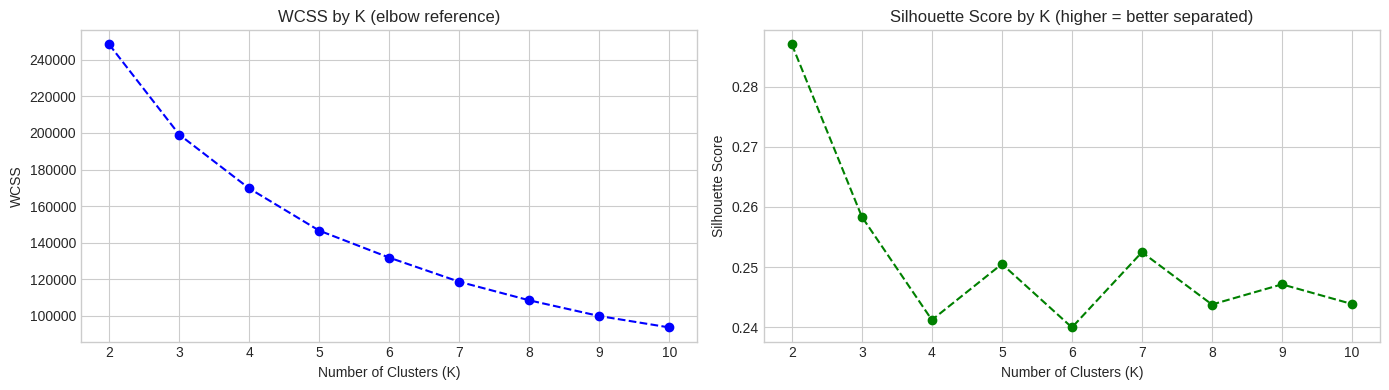

Best silhouette score at K = 2 (0.287)


,Inventory_Level,Sales_Velocity,Days_of_Supply,Lead_Time_Days,Storage_Cost
Cluster,,,,,
0,606.508728,12.062734,62.478149,8.141694,93.916027
1,337.099512,27.122591,12.345714,7.978852,48.189736
2,543.277556,26.496088,20.308222,7.996001,83.791739
3,393.359716,12.448889,36.850713,7.827914,55.686190


In [84]:
# standardize, PCA, elbow + silhouette scoring, then final KMeans fit
features = ["Inventory_Level", "Sales_Velocity", "Days_of_Supply", "Lead_Time_Days", "Storage_Cost"]

X_train_cluster = train_df[features]
X_test_cluster = test_df[features]

scaler = PowerTransformer()
X_train_scaled = scaler.fit_transform(X_train_cluster)
X_test_scaled = scaler.transform(X_test_cluster)

pca = PCA(n_components=3, random_state=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)


k_range = range(2, 11)
wcss = []
sil_scores = []

rng = np.random.RandomState(2)
sample_idx = rng.choice(len(X_train_pca), size=50000, replace=False)
X_sample = X_train_pca[sample_idx]

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, init='k-means++', random_state=2, n_init=10)
    labels = kmeans_temp.fit_predict(X_train_pca)
    wcss.append(kmeans_temp.inertia_)
    sil_scores.append(silhouette_score(X_sample, labels[sample_idx]))

metrics_df = pd.DataFrame({'K': list(k_range), 'WCSS': wcss, 'Silhouette': sil_scores})
display(metrics_df)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(metrics_df['K'], metrics_df['WCSS'], marker='o', linestyle='--', color='b')
ax[0].set_title('WCSS by K (elbow reference)')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('WCSS')
ax[0].grid(True)

ax[1].plot(metrics_df['K'], metrics_df['Silhouette'], marker='o', linestyle='--', color='g')
ax[1].set_title('Silhouette Score by K (higher = better separated)')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')
ax[1].grid(True)
plt.tight_layout()
plt.show()

best_k = int(metrics_df.loc[metrics_df['Silhouette'].idxmax(), 'K'])
print(f"Best silhouette score at K = {best_k} ({metrics_df['Silhouette'].max():.3f})")


N_CLUSTERS = 4

kmeans = KMeans(n_clusters=N_CLUSTERS, init='k-means++', random_state=2, n_init=10)

train_df = train_df.copy()
test_df = test_df.copy()

train_df['Cluster'] = kmeans.fit_predict(X_train_pca)
test_df['Cluster'] = kmeans.predict(X_test_pca)

cluster_profiles = train_df.groupby('Cluster')[features].mean()
display(cluster_profiles)

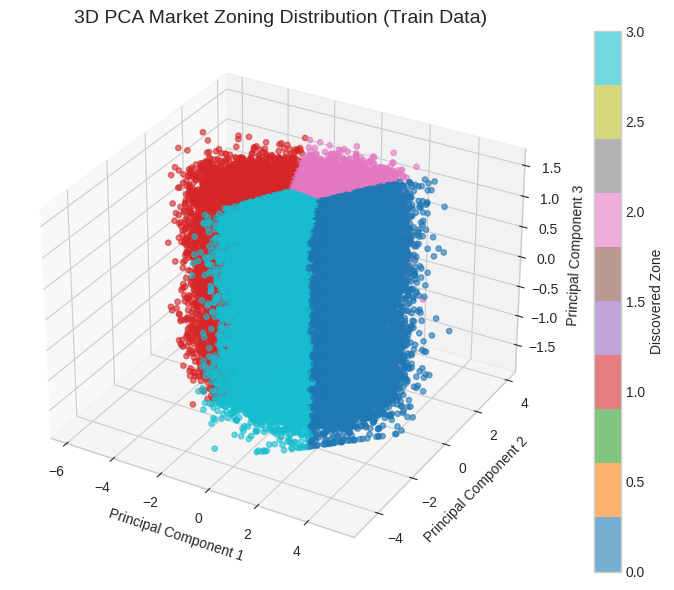

In [85]:
#3D scatter visualization of the clustered market zones using PCA.
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_train_pca[:, 0], 
    X_train_pca[:, 1], 
    X_train_pca[:, 2], 
    c=train_df['Cluster'], 
    cmap='tab10', 
    s=15, 
    alpha=0.6
)

ax.set_title("3D PCA Market Zoning Distribution (Train Data)", fontsize=14)
ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_zlabel("Principal Component 3")
plt.colorbar(scatter, label='Discovered Zone')
plt.tight_layout()
plt.show()

Accuracy on Unseen Data: 88.99%

              precision    recall  f1-score   support

           0       0.89      0.91      0.90      3058
           1       0.92      0.90      0.91      3330
           2       0.88      0.90      0.89      4021
           3       0.87      0.85      0.86      3279

    accuracy                           0.89     13688
   macro avg       0.89      0.89      0.89     13688
weighted avg       0.89      0.89      0.89     13688



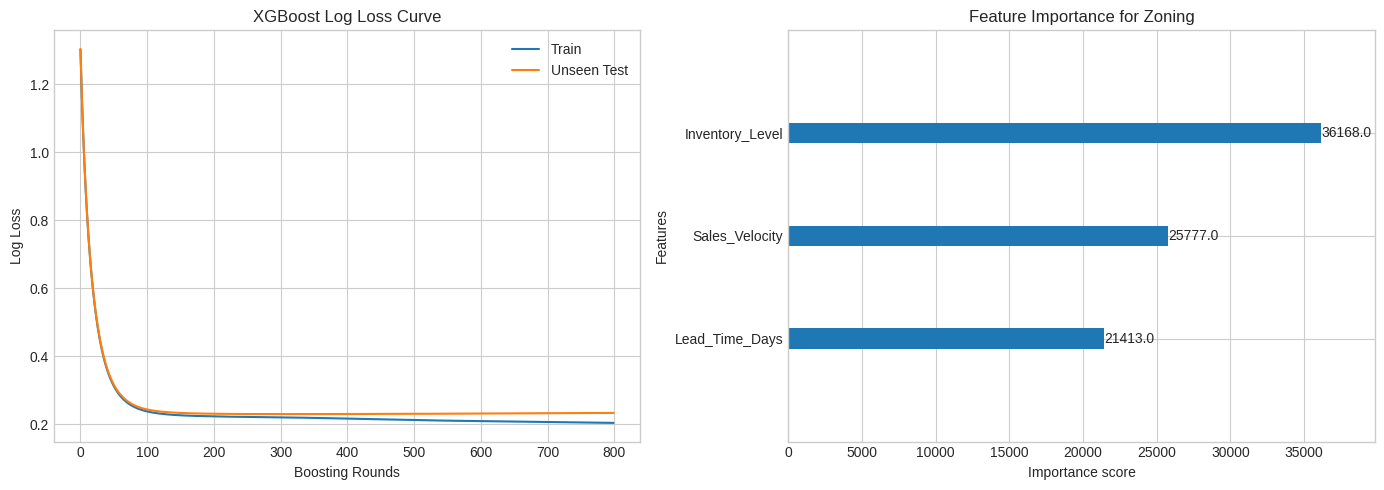

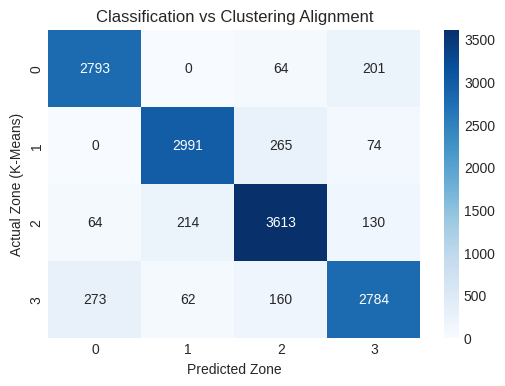

In [86]:
#XGBoost classifier on the training set
clf_features = ["Inventory_Level", "Sales_Velocity", "Lead_Time_Days"]

X_train = train_df[clf_features]
y_train = train_df['Cluster']
X_test = test_df[clf_features]
y_test = test_df['Cluster']

xgb = XGBClassifier(
    n_estimators=800, max_depth=6, learning_rate=0.05, 
    eval_metric='mlogloss', random_state=2
)

eval_set = [(X_train, y_train), (X_test, y_test)]
xgb.fit(X_train, y_train, eval_set=eval_set, verbose=False)

y_pred = xgb.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Accuracy on Unseen Data: {acc * 100:.2f}%\n")
print(classification_report(y_test, y_pred))

results = xgb.evals_result()
epochs = len(results['validation_0']['mlogloss'])
x_axis = range(0, epochs)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(x_axis, results['validation_0']['mlogloss'], label='Train')
ax[0].plot(x_axis, results['validation_1']['mlogloss'], label='Unseen Test')
ax[0].legend()
ax[0].set_title('XGBoost Log Loss Curve')
ax[0].set_ylabel('Log Loss')
ax[0].set_xlabel('Boosting Rounds')

plot_importance(xgb, ax=ax[1], title='Feature Importance for Zoning')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Classification vs Clustering Alignment")
plt.xlabel("Predicted Zone")
plt.ylabel("Actual Zone (K-Means)")
plt.show()

In [87]:
# inference
incoming_feed = pd.DataFrame({
    "Inventory_Level": [5300, 85, 1080, 20],
    "Sales_Velocity": [18, 340, 105, 5],
    "Lead_Time_Days": [6.0, 16.0, 3.5, 21.0]
})

predicted_zones = xgb.predict(incoming_feed)
probabilities = xgb.predict_proba(incoming_feed)

results_df = incoming_feed.copy()
results_df['Predicted_Zone_Class'] = predicted_zones
results_df['Prediction_Confidence'] = [f"{max(probs)*100:.1f}%" for probs in probabilities]

display(results_df)

,Inventory_Level,Sales_Velocity,Lead_Time_Days,Predicted_Zone_Class,Prediction_Confidence
0,5300,18,6.0,0,100.0%
1,85,340,16.0,1,100.0%
2,1080,105,3.5,2,99.6%
3,20,5,21.0,3,99.8%
